# 03 · Distributions and Relationship with the Target

**Objective:** describe how each variable in the dataset is distributed and how it relates to the
target `is_canceled`, in order to identify which variables are useful for predicting booking
cancellations and which transformations they will need before modelling (encoding, binning, scaling).

**Scope:**
- Includes: variable inventory and data types, class balance of the target, distributions of
  numerical and categorical variables, cancellation rate by variable, and a preliminary selection of
  useful variables, including a check for variables not available at booking time (data leakage).
- Does not include: duplicates, missing and erroneous values (→ `01_cleaning`), or outlier
  detection and treatment (→ `02_outliers`).

**Data:** the clean dataset produced by `01_cleaning` (`data/hotels_clean.csv`, 86,621 bookings ×
32 columns, after removing duplicates and invalid rows). Run `01_cleaning` first to create it.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("pandas", pd.__version__, "| seaborn", sns.__version__)

pandas 3.0.6 | seaborn 0.13.2


In [2]:
csv_path = "../data/hotels_clean.csv"   # created by 01_cleaning.ipynb (run it first)
df = pd.read_csv(csv_path)
df.shape

(86621, 32)

## 1. Variable inventory

In [3]:
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,No agent,No company,0,Transient,75.0,0,0,Check-Out,2015-07-02
1,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304,No company,0,Transient,75.0,0,0,Check-Out,2015-07-02
2,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240,No company,0,Transient,98.0,0,1,Check-Out,2015-07-03
3,Resort Hotel,0,0,2015,July,27,1,0,2,2,...,No Deposit,No agent,No company,0,Transient,107.0,0,0,Check-Out,2015-07-03
4,Resort Hotel,0,9,2015,July,27,1,0,2,2,...,No Deposit,303,No company,0,Transient,103.0,0,1,Check-Out,2015-07-03


In [4]:
inventory = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_unique": df.nunique(),
    "n_missing": df.isna().sum(),
    "example": df.iloc[0],
})
inventory

,dtype,n_unique,n_missing,example
hotel,str,2,0,Resort Hotel
is_canceled,int64,2,0,0
lead_time,int64,478,0,7
arrival_date_year,int64,3,0,2015
arrival_date_month,str,12,0,July
arrival_date_week_number,int64,53,0,27
arrival_date_day_of_month,int64,31,0,1
stays_in_weekend_nights,int64,17,0,0
stays_in_week_nights,int64,33,0,1
adults,int64,7,0,1


In [5]:
target = "is_canceled"
numerical_continuous = ["adr", "lead_time", "days_in_waiting_list"]
numerical_counts = ["adults", "children", "babies", "previous_cancellations","previous_bookings_not_canceled", "booking_changes", "required_car_parking_spaces", "total_of_special_requests", "stays_in_weekend_nights", "stays_in_week_nights"]
binary = ["is_repeated_guest"]
categorical = ["meal", "hotel", "deposit_type", "reserved_room_type", "assigned_room_type", "customer_type", "market_segment", "distribution_channel", "country"]
id_codes = ["agent", "company"]
date_parts = ["arrival_date_year", "arrival_date_month", "arrival_date_week_number", "arrival_date_day_of_month"]
leakage = ["reservation_status", "reservation_status_date"]

In [6]:
all_columns = [target] + numerical_continuous + numerical_counts + binary + categorical + id_codes + date_parts + leakage

print(len(all_columns), "assigned |", len(df.columns), "in the dataset")
print("Every column assigned exactly once: ", sorted(all_columns) == sorted(df.columns))

32 assigned | 32 in the dataset
Every column assigned exactly once:  True


### Conclusions and actions: variable inventory

**Conclusions**

- After cleaning, the dataset has 86,621 bookings and 32 columns. It started with 119,390;
  `01_cleaning` removed the duplicates and the invalid rows. There are no missing values left.

- Sorting the columns by what they mean gives: 1 target, 3 continuous, 10 counts, 1 binary,
  9 categorical, 2 ID codes, 4 parts of the arrival date and 2 leakage columns.

- The type pandas gives a column doesn't always match what it means:
  - `is_canceled` and `is_repeated_guest` look like numbers, but they are just yes/no (0/1).
  - `agent` and `company` are codes, not quantities: agent 240 isn't "more" than agent 9. In the raw
    file they were `float` because of the `NULL` values; `01_cleaning` replaced those with
    "No agent" / "No company", so they are now text.
  - `arrival_date_month` and `reservation_status_date` are stored as text, not as dates.

- `reservation_status` gives away the answer: every Canceled (22,972) and No-Show (999) booking has
  `is_canceled = 1`, and every Check-Out (62,650) has `is_canceled = 0`. `reservation_status_date`
  is the date of that final status. Both are only known once the booking is over, so they can't be
  used to predict it.

**Actions**

- Use a different analysis for each group: histograms and boxplots for continuous variables, bar
  charts for counts, and frequency tables with the cancellation rate per category for the rest.

- Put the months in calendar order before plotting (alphabetically, April would come first).

- Treat `agent` and `company` as categories and never average them. They have hundreds of codes,
  so the rare ones will have to be grouped before modelling.

- Leave `reservation_status` and `reservation_status_date` out of the features and explain why in
  the README. Three more columns (`booking_changes`, `assigned_room_type`, `days_in_waiting_list`)
  might also only be known after booking; we keep them for now and check them in the leakage section.

## 2. Target: class balance

In [7]:
counts = df[target].value_counts()
proportions = df[target].value_counts(normalize=True)
pd.DataFrame({"count": counts, "proportion": proportions.round(3)})

,count,proportion
is_canceled,,
0,62650,0.723
1,23971,0.277


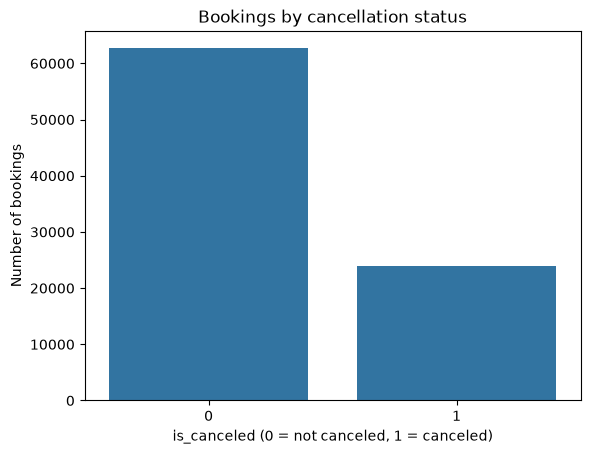

In [8]:
sns.countplot(data=df, x=target)
plt.title("Bookings by cancellation status")
plt.xlabel("is_canceled (0 = not canceled, 1 = canceled)")
plt.ylabel("Number of bookings")
plt.show()

### Conclusions and actions: target

**Conclusions**

- After cleaning, 23,971 of the 86,621 bookings were cancelled (27.7%) and 62,650 were not (72.3%).
  In other words, a bit more than one booking in four ends up cancelled. The bar chart shows it:
  the "not canceled" bar is about two and a half times taller than the "canceled" one.

- In the raw file the rate was 37%. The drop comes from the duplicates removed in `01_cleaning`:
  63% of them were cancellations, so removing them took out far more cancelled bookings than
  non-cancelled ones. The cleaning didn't just make the dataset smaller, it changed the target.

- The two classes are not balanced, but this isn't an extreme case like fraud detection, where
  positives can be 1% or less. There are enough cancellations for a model to learn from.

- The imbalance does matter when judging a model. A "model" that always answers "not canceled"
  would be right 72.3% of the time without detecting a single cancellation. So any real model has
  to beat 72.3% accuracy, and accuracy alone won't tell us whether it actually finds cancellations.

- The cancelled class also includes 999 No-Shows (4.2% of all cancellations). We keep them
  together: for the hotel, a guest who cancels and a guest who doesn't turn up both leave an empty
  room. The only difference is that a cancellation gives the hotel some time to resell the room.

**Actions**

- Use 27.7% as the reference rate in the next sections: a group of bookings is higher risk only if
  its cancellation rate is clearly above it.

- When building the model, split train and test in a stratified way, so both keep the 72/28
  proportion, and report recall (sensitivity), precision and AUC next to accuracy, always compared
  with the 72.3% baseline.

- In the README, define the positive class as "cancelled or no-show" and add the class balance
  (27.7% cancelled) to the problem formulation, where it is still marked "to be completed".

## 3. Distributions

### 3a. Continuous variables

The per-hotel distributions and outliers of `adr` and `lead_time` are in `02_outliers`.
Here they are split by cancellation status instead.

In [9]:
df[numerical_continuous].describe().T   # transposed (swaps rows and columns)

,count,mean,std,min,25%,50%,75%,max
adr,86621.0,107.201044,51.293203,0.0,72.9,99.0,134.46,510.0
lead_time,86621.0,80.255019,86.022475,0.0,12.0,50.0,125.00,709.0
days_in_waiting_list,86621.0,0.750407,10.030459,0.0,0.0,0.0,0.00,391.0


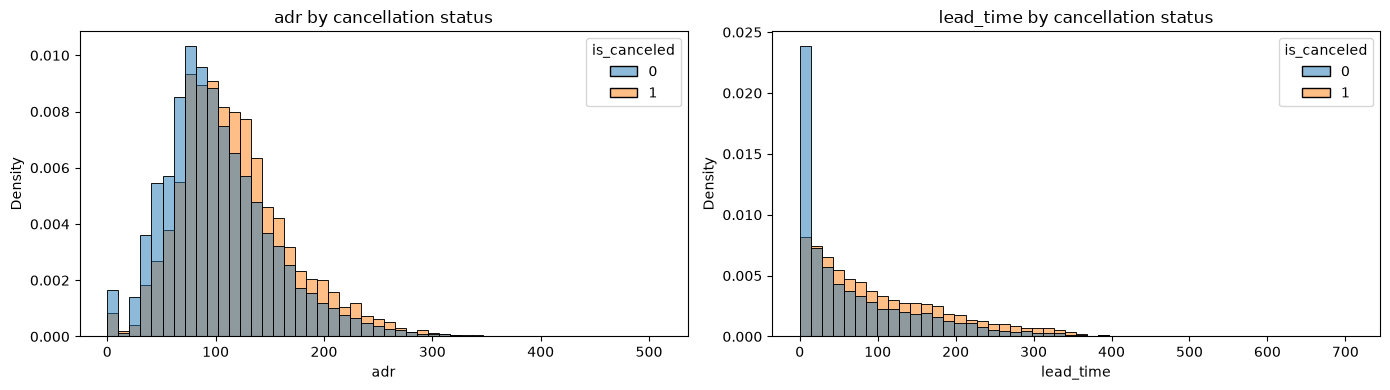

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(data=df, x="adr", hue=target, stat="density", common_norm=False,
             bins=50, ax=axes[0])
axes[0].set_title("adr by cancellation status")

sns.histplot(data=df, x="lead_time", hue=target, stat="density", common_norm=False,
             bins=50, ax=axes[1])
axes[1].set_title("lead_time by cancellation status")

plt.tight_layout()
plt.show()

There are 2.6 times more non-cancelled bookings, so with raw counts the “canceled” bars would always look smaller. ``stat="density"`` and ``common_norm=False`` scale each class to the same total, so we compare the shapes: where each class’s bookings concentrate.

In [11]:
df.groupby(target)[["adr", "lead_time"]].median()

,adr,lead_time
is_canceled,,
0,95.0,38.0
1,109.8,80.0


In [12]:
print("Share with 0 days:", (df["days_in_waiting_list"] == 0).mean().round(3))
df.loc[df["days_in_waiting_list"] > 0, "days_in_waiting_list"].describe()

Share with 0 days: 0.99


count    854.000000
mean      76.113583
std       66.886599
min        1.000000
25%       33.000000
50%       59.000000
75%       99.000000
max      391.000000
Name: days_in_waiting_list, dtype: float64

### Conclusions and actions: continuous variables

**Conclusions**

- All three variables have a long tail to the right: the mean is above the median in every case.
  The tail is mild for `adr` (mean 107, median 99), clear for `lead_time` (80 vs 50) and extreme
  for `days_in_waiting_list` (0.75 vs 0).

- `lead_time` is where cancelled and non-cancelled bookings differ the most. Bookings that go ahead
  pile up in the first two weeks (the tall blue bar on the left), while cancelled ones are spread
  over longer lead times. The median is 38 days for bookings that go ahead and 80 days for cancelled
  ones: the further ahead a booking is made, the more time there is for plans to change.

- `adr`: the two distributions overlap a lot, so price on its own won't separate the classes well.
  Still, very cheap bookings (below about 50 per night) are mostly not cancelled, and cancelled
  bookings are a bit more frequent from about 100 per night upwards (median about 110 vs 95).

- `days_in_waiting_list`: 99% of bookings never waited. Only 854 did, with a median wait of 59 days.
  As a number of days, the variable is almost always 0.

**Actions**

- `lead_time`: probably one of the most useful features. Check the cancellation rate by range in
  section 4. Because of the long tail, use bins or a log transform for models that are sensitive to
  skewed variables (e.g. logistic regression); tree-based models don't need it.

- `adr`: keep it, but don't expect much from it on its own; compare the cancellation rate by price
  range in section 4. The 5,400 booking (a data entry error) is removed in `01_cleaning`, so it no
  longer affects the plots.

- `days_in_waiting_list`: replace the number of days with a yes/no variable ("was on the waiting
  list"). It is also a leakage candidate, since the wait happens after the booking is made, so it is
  reviewed in section 5.

### 3b. Count variables

Total length of stay (`total_nights`) is analysed in `02_outliers`; here each count is looked at on its own.

In [13]:
counts_summary = pd.DataFrame({
    "share_zero": (df[numerical_counts] == 0).mean().round(3),
    "median": df[numerical_counts].median(),
    "max": df[numerical_counts].max(),
    "n_unique": df[numerical_counts].nunique(),
})
counts_summary.sort_values("share_zero", ascending=False)

,share_zero,median,max,n_unique
babies,0.990,0.0,2,3
previous_cancellations,0.981,0.0,26,15
previous_bookings_not_canceled,0.960,0.0,72,73
required_car_parking_spaces,0.916,0.0,8,5
children,0.904,0.0,3,4
booking_changes,0.819,0.0,18,19
total_of_special_requests,0.501,0.0,5,6
stays_in_weekend_nights,0.398,1.0,19,17
stays_in_week_nights,0.064,2.0,50,33
adults,0.003,2.0,6,7


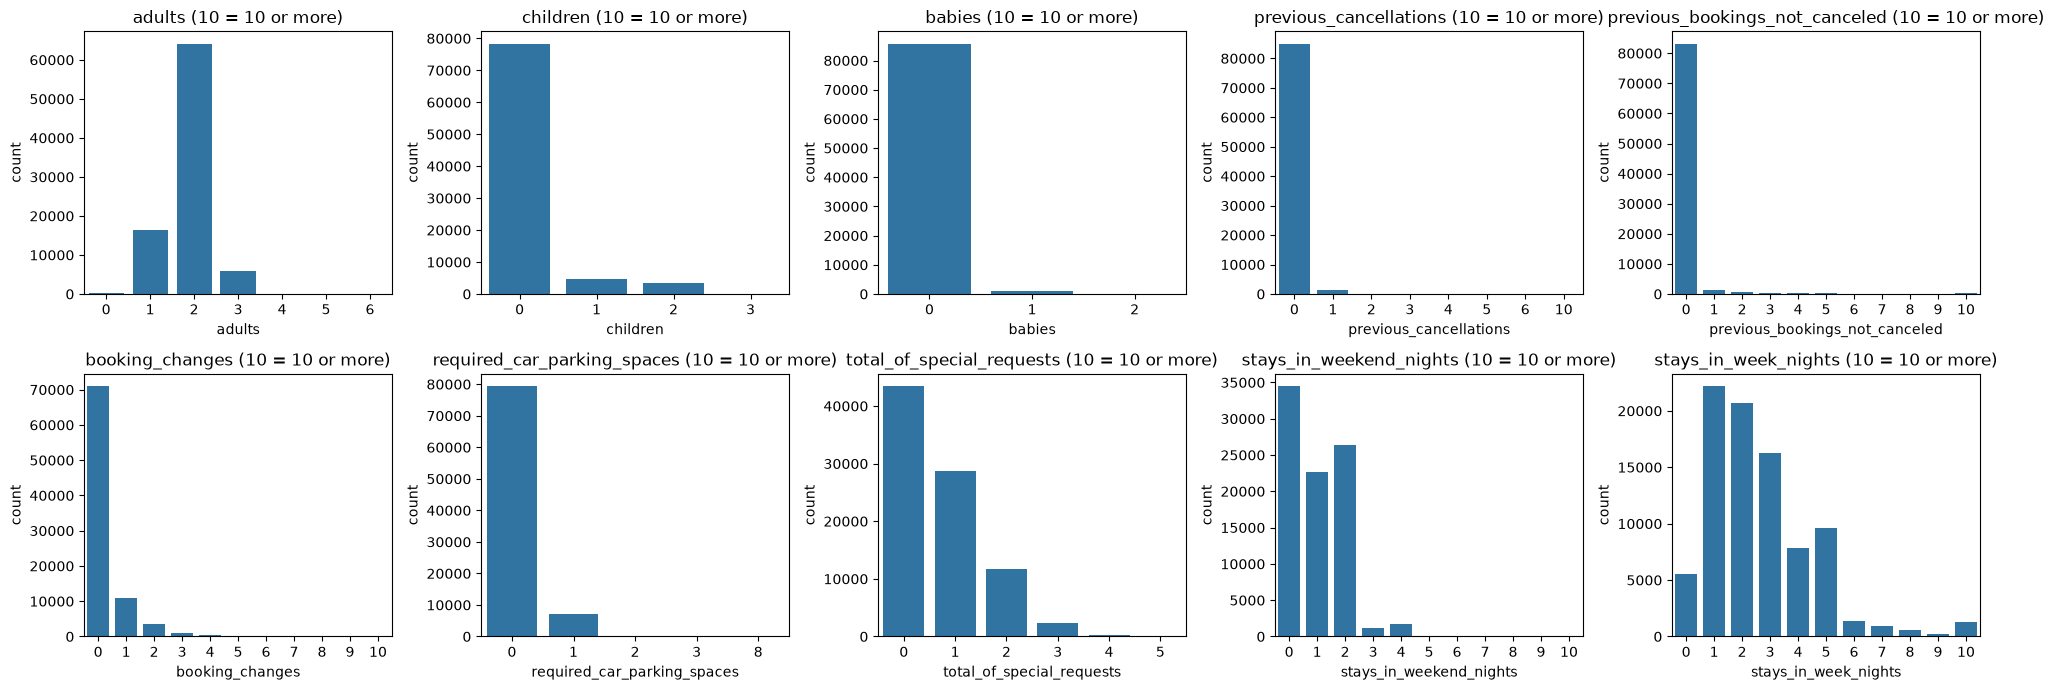

In [14]:
fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for ax, var in zip(axes.flat, numerical_counts):
    sns.countplot(x=df[var].clip(upper=10), ax=ax)
    ax.set_title(f"{var} (10 = 10 or more)")
plt.tight_layout()
plt.show()

Some counts go up to 50 or more (`stays_in_week_nights`, `previous_bookings_not_canceled`), which would give unreadable plots with dozens of tiny bars. That's why we use `.clip(upper=10)`: every value of 10 or more is grouped into the last bar, labelled 10.

### Conclusions and actions: count variables

**Conclusions**

- Most counts are almost always 0. Five are 0 for at least 90% of bookings: `babies` (99.0%),
  `previous_cancellations` (98.1%), `previous_bookings_not_canceled` (96.0%),
  `required_car_parking_spaces` (91.6%) and `children` (90.4%). `booking_changes` is close (81.9%).
  For these, what matters is mostly whether the value is 0 or not, not the exact number.

- The maximums are far from the typical values (26 previous cancellations, 72 previous bookings,
  8 parking spaces), but they are very rare. `02_outliers` leaves these counts out of the IQR
  analysis because their IQR is 0.

- The other counts have a real spread. `adults` is almost always 1 to 3, with 2 by far the most common
  (couples); only 0.3% have 0 adults, the bookings with children only that `01_cleaning` kept.
  Week nights are usually 1 to 4, with a small peak at 5 (a full working week), and weekend nights
  are 0, 1 or 2. Half of the bookings make no special request, and most of the rest make one or two.

**Actions**

- Turn the mostly-zero counts into yes/no variables: has children or babies, has cancelled before,
  has previous bookings, has changed the booking, has asked for parking. Section 4 checks whether
  these groups cancel at different rates.

- Keep `adults`, the nights and `total_of_special_requests` as counts, grouping the rare high values
  (e.g. "4 or more") if a model needs it.

- `booking_changes` and `required_car_parking_spaces` are leakage candidates: changes are counted
  until check-in or cancellation, and a parking space may only be recorded when the guest arrives
  with a car. Both are reviewed in section 5.

### 3c. Categorical, binary and date variables

In [15]:
cat_cols = categorical + id_codes + binary
cat_summary = pd.DataFrame({
    "n_categories": df[cat_cols].nunique(),
    "most_frequent": df[cat_cols].mode().iloc[0],
    "top_share": df[cat_cols].apply(lambda s: s.value_counts(normalize=True).iloc[0]).round(3),
    "n_rare (<1%)": df[cat_cols].apply(lambda s: (s.value_counts(normalize=True) < 0.01).sum()),
})
cat_summary.sort_values("n_categories", ascending=False)

,n_categories,most_frequent,top_share,n_rare (<1%)
company,348,No company,0.940,347
agent,334,9,0.331,322
country,178,PRT,0.310,164
assigned_room_type,11,A,0.532,4
reserved_room_type,9,A,0.646,2
market_segment,8,Online TA,0.592,3
meal,5,BB,0.778,2
distribution_channel,5,TA/TO,0.792,2
customer_type,4,Transient,0.824,1
deposit_type,3,No Deposit,0.987,1


- ``top_share`` is how much of the data the most common category takes. Close to 1 means the variable barely varies.

- ``n_rare`` is how many categories hold less than 1% of bookings each. Those are candidates for grouping into “Other”.

- ``lambda s``: ``apply`` runs once per column, where ``s`` is that column.

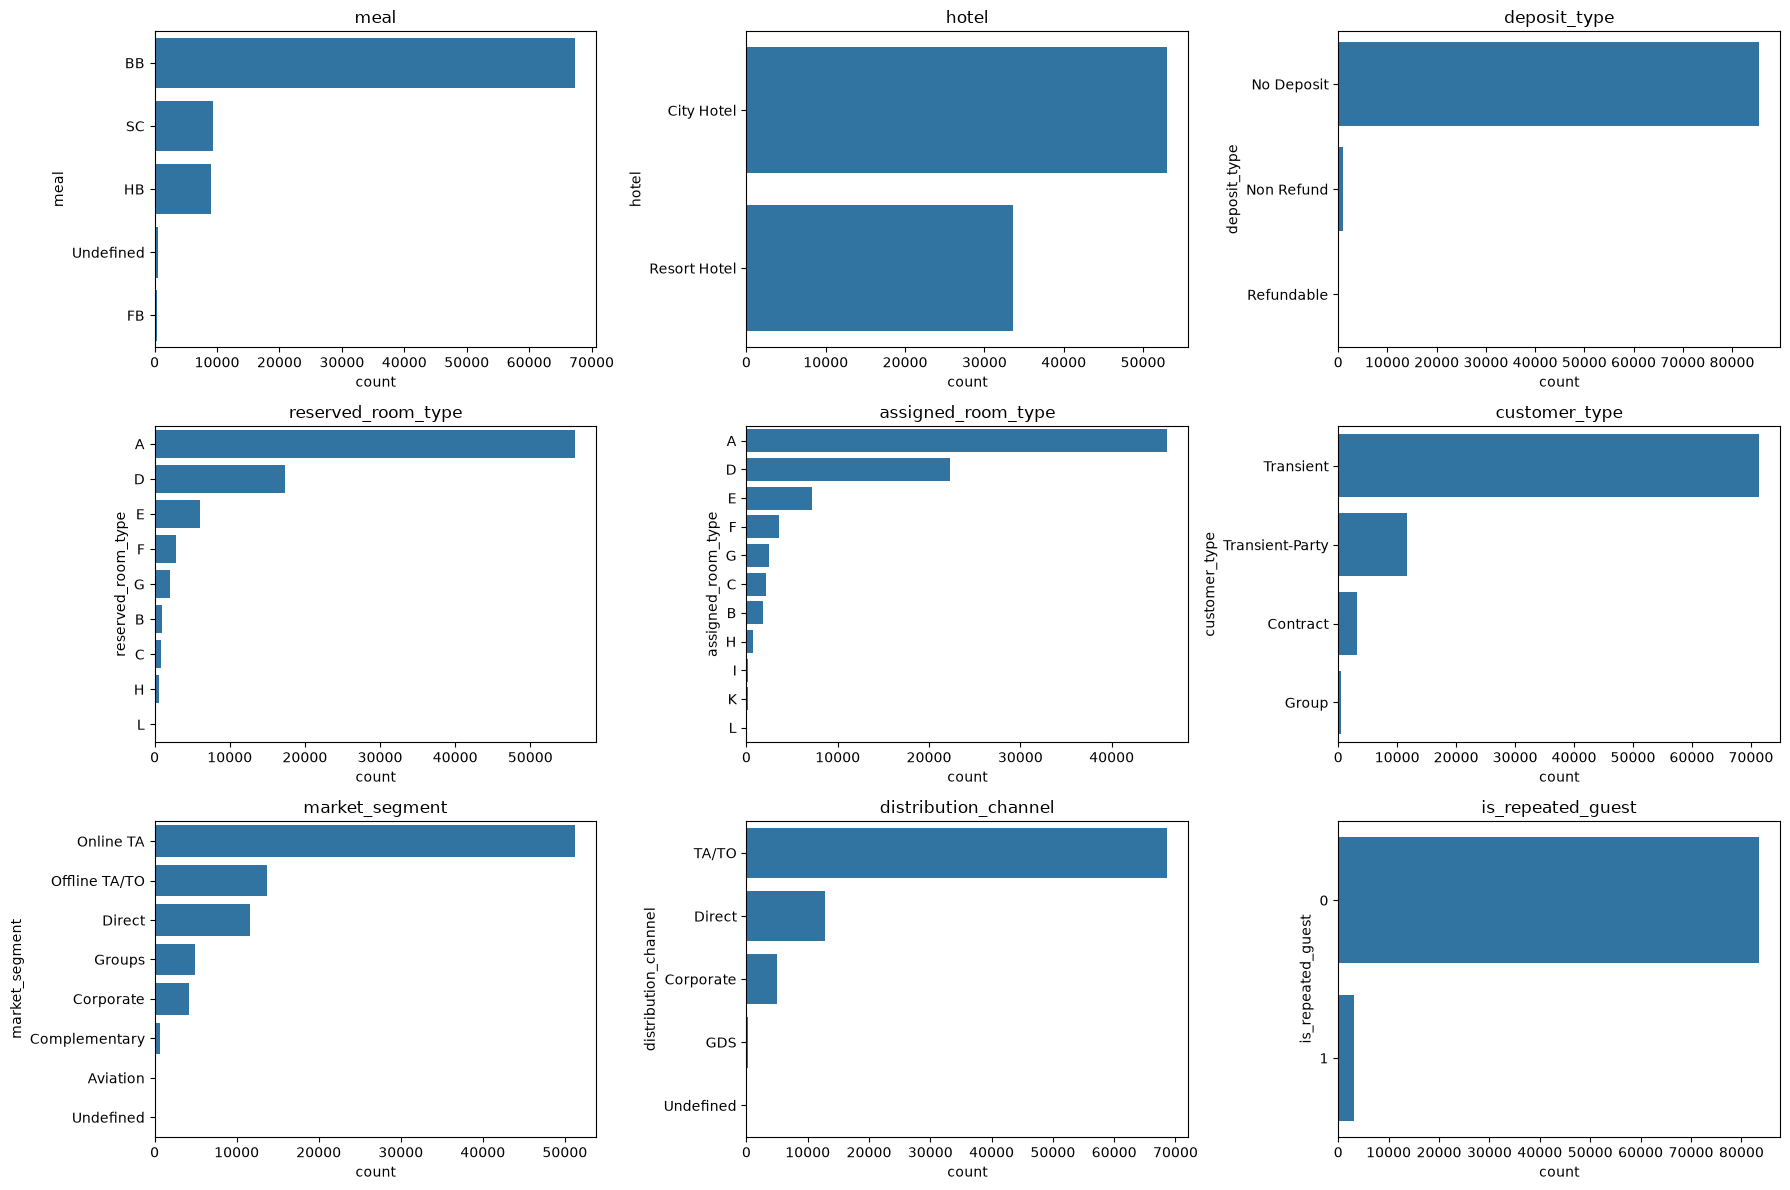

In [16]:
low_card = [c for c in categorical + binary if df[c].nunique() <= 15]
fig, axes = plt.subplots(3, 3, figsize=(18, 12))
for ax, var in zip(axes.flat, low_card):
    order = df[var].value_counts().index
    sns.countplot(data=df, y=var, order=order, ax=ax)
    ax.set_title(var)
plt.tight_layout()
plt.show()

Only the variables with up to 15 categories are plotted here (`country`, with 178, is left out).
The bars are horizontal so long labels stay readable, and sorted from most to least frequent.

In [17]:
for var in ["country", "agent", "company"]:
    top10_share = df[var].value_counts(normalize=True).head(10).sum()
    print(f"{var}: {df[var].nunique()} categories, top 10 cover {top10_share:.1%}")
    print(df[var].value_counts().head(5), "\n")

country: 178 categories, top 10 cover 81.6%
country
PRT    26848
GBR    10399
FRA     8813
ESP     7228
DEU     5385
Name: count, dtype: int64 

agent: 334 categories, top 10 cover 79.2%
agent
9           28653
240         12907
No agent    11950
14           3329
7            3282
Name: count, dtype: int64 

company: 348 categories, top 10 cover 96.8%
company
No company    81451
40              844
223             492
45              230
153             201
Name: count, dtype: int64 



`country`, `agent` and `company` have hundreds of categories, so instead of plotting them we check
how much of the data their 10 most frequent values cover.

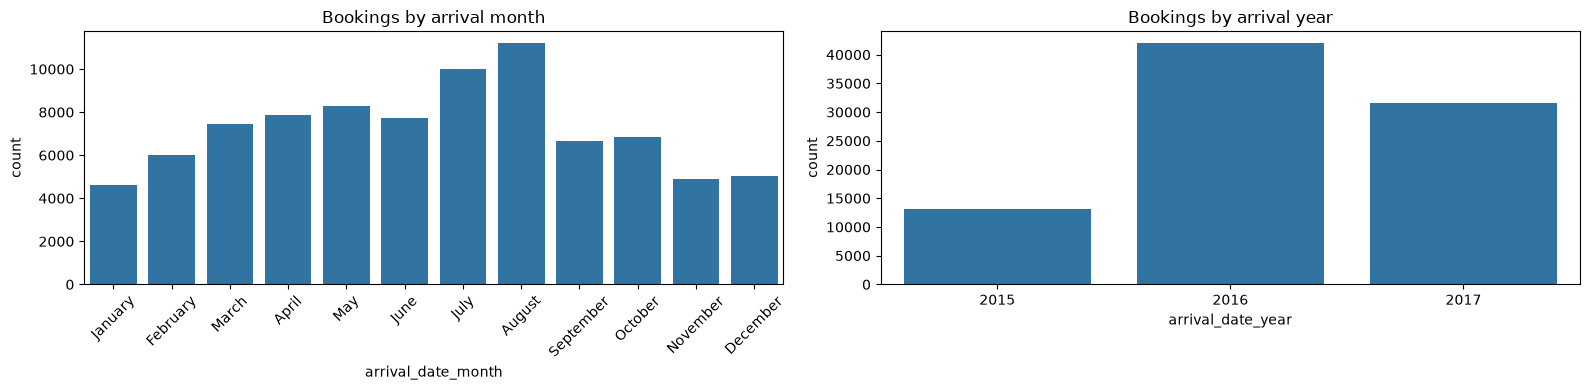

In [18]:
month_order = ["January", "February", "March", "April", "May", "June",
               "July", "August", "September", "October", "November", "December"]
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
sns.countplot(data=df, x="arrival_date_month", order=month_order, ax=axes[0])
axes[0].tick_params(axis="x", rotation=45)
axes[0].set_title("Bookings by arrival month")
sns.countplot(data=df, x="arrival_date_year", ax=axes[1])
axes[1].set_title("Bookings by arrival year")
plt.tight_layout()
plt.show()

Months are plotted in calendar order, as planned in the inventory. The data covers arrivals from
July 2015 to August 2017, so 2015 and 2017 are incomplete years, and July and August appear in three
years while the other months appear in only two.

### Conclusions and actions: categorical, binary and date variables

**Conclusions**

- Several variables are dominated by one category: `deposit_type` (98.7% "No Deposit"),
  `is_repeated_guest` (96.4% not repeated), `company` (94.0% "No company"), `customer_type`
  (82.4% Transient), `distribution_channel` (79.2% TA/TO) and `meal` (77.8% BB). A small group can
  still matter if it cancels very differently, which section 4 checks (for example the 1,037
  "Non Refund" deposits).

- Some categories are tiny or unclear: `market_segment` has "Complementary" (682), "Aviation" (222)
  and "Undefined" (2), and `distribution_channel` has "GDS" (178) and "Undefined" (5). In `meal`,
  "Undefined" (485) means the same as "SC" (no meal package), according to the dataset documentation.

- `country`, `agent` and `company` have hundreds of categories, but a few cover most bookings: the
  top 10 countries cover 81.6% (Portugal alone 31.0%), the top 10 agents 79.2%, and for `company`
  almost every booking is "No company".

- `assigned_room_type` has two room types that never appear as reserved (I and K), and fewer bookings
  end up in room A than reserved it. The assigned room is decided by the hotel, often at check-in,
  which makes it a leakage candidate.

- By raw counts, August and July are the busiest months, but they appear in three years of data and
  the other months in only two, so the counts overstate them. 2015 (6 months) and 2017 (8 months)
  are incomplete years.

**Actions**

- Merge "Undefined" into "SC" in `meal`, and group the rare categories of `market_segment` and
  `distribution_channel` into "Other". "Complementary" is decided after section 4, since free stays
  may cancel differently.

- Keep the top 10 countries and agents and group the rest as "Other"; reduce `company` to a yes/no
  variable ("booked through a company").

- Compare months by cancellation rate (section 4), not by number of bookings. Don't use
  `arrival_date_year` as a feature: a model is applied to future years it has never seen, and the
  month already captures the season. `arrival_date_week_number` repeats the month's information.

- `assigned_room_type` joins the leakage candidates for section 5; `reserved_room_type` is known at
  booking and can be used instead.

## 4. Relationship with the target
For each variable, the cancellation rate is computed per group and compared with the overall rate
(27.7%). The number of bookings is shown next to each rate, so small groups aren't over-interpreted.

### 4a. Continuous variables by range

In [19]:
overall_rate = df[target].mean() * 100

def cancel_rate(by):
    table = df.groupby(by, observed=True)[target].agg(bookings="count", cancel_rate="mean")
    table["cancel_rate"] = (table["cancel_rate"] * 100).round(1)
    table["diff_vs_overall"] = (table["cancel_rate"] - overall_rate).round(1)
    return table

`cancel_rate` groups the bookings and returns, for each group, the number of bookings, the % that were cancelled and the difference with the overall rate in percentage points. It uses the fact that the mean of a 0/1 column is the share of 1s. The same function is used for every variable in this section.

In [20]:
lead_range = pd.cut(df["lead_time"], bins=[-1, 7, 30, 90, 180, 365, df["lead_time"].max()],
                    labels=["0-7", "8-30", "31-90", "91-180", "181-365", "366+"])
lead_table = cancel_rate(lead_range)
lead_table

,bookings,cancel_rate,diff_vs_overall
lead_time,,,
0-7,17855,8.5,-19.2
8-30,16233,25.5,-2.2
31-90,22631,32.1,4.4
91-180,18190,35.1,7.4
181-365,11151,39.7,12.0
366+,561,41.0,13.3


`pd.cut` splits `lead_time` into ranges that mean something for a hotel: booked in the last week, the last month, three months, six months, a year, or more than a year in advance.

In [21]:
adr_range = pd.cut(df["adr"], bins=[-0.01, 50, 100, 150, 200, df["adr"].max()],
                   labels=["0-50", "50-100", "100-150", "150-200", "200+"])
adr_table = cancel_rate(adr_range)
wait_table = cancel_rate(df["days_in_waiting_list"] > 0)
display(adr_table, wait_table)

,bookings,cancel_rate,diff_vs_overall
adr,,,
0-50,9104,15.6,-12.1
50-100,35779,24.5,-3.2
100-150,26629,31.9,4.2
150-200,10392,34.0,6.3
200+,4717,37.6,9.9


,bookings,cancel_rate,diff_vs_overall
days_in_waiting_list,,,
False,85767,27.6,-0.1
True,854,34.4,6.7


`adr` is split into ranges of 50 per night, up to the maximum rate. The waiting list is turned into
yes/no (`> 0`), as proposed in section 3a.

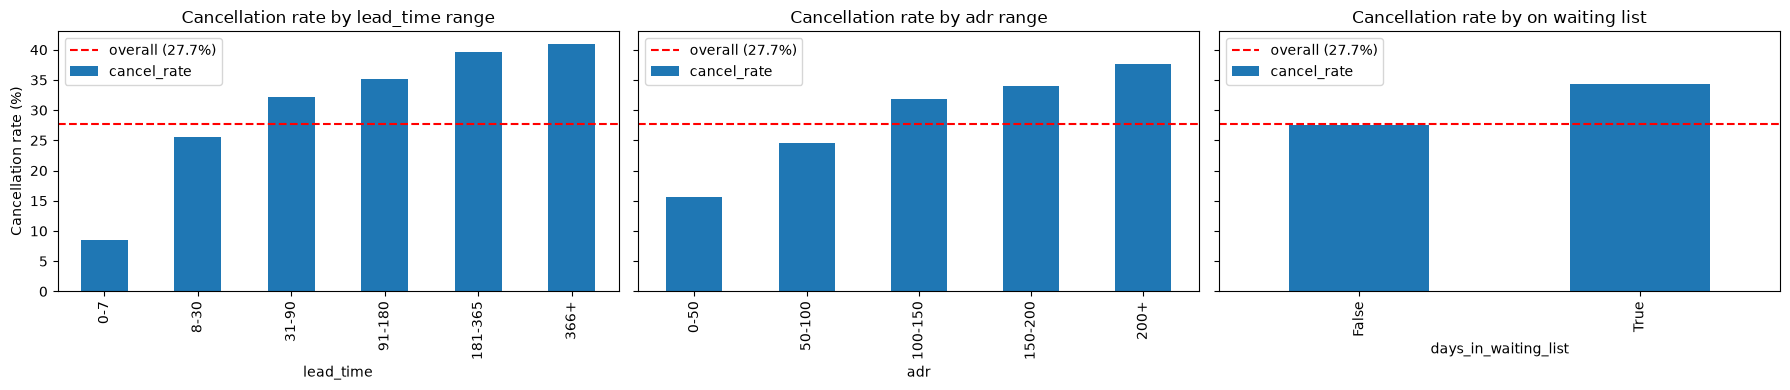

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4), sharey=True)
tables = {"lead_time range": lead_table, "adr range": adr_table, "on waiting list": wait_table}
for ax, (name, table) in zip(axes, tables.items()):
    table["cancel_rate"].plot(kind="bar", ax=ax)
    ax.axhline(overall_rate, color="red", linestyle="--", label=f"overall ({overall_rate:.1f}%)")
    ax.set_title(f"Cancellation rate by {name}")
    ax.legend()
axes[0].set_ylabel("Cancellation rate (%)")
plt.tight_layout()
plt.show()

Bars above the red dashed line are groups that cancel more than average; bars below it, less.

### Conclusions and actions: continuous variables vs. the target

**Conclusions**

- `lead_time` shows the clearest pattern: the cancellation rate goes up in every range, from 8.5%
  for bookings made a week or less ahead to about 40% for bookings made more than six months ahead.
  Last-minute bookings almost never get cancelled. The "366+" group is small (561 bookings) but
  follows the same trend.

- `adr` also rises steadily with the price: 15.6% below 50 per night and 37.6% above 200. The
  histograms in section 3a overlapped a lot, but grouped into ranges the trend is clear. Part of it
  may come from other variables: the cheapest rates include free *Complementary* stays, and the most
  expensive ones fall in high season, so `adr` shouldn't be read on its own.

- Bookings that were on the waiting list are cancelled more often (34.4% vs 27.6%), but they are only
  854 bookings, so the effect on the whole dataset is small.

**Actions**

- `lead_time` is a strong candidate feature. Use it in ranges like these, or with a log transform, for
  models that are sensitive to skewed variables.

- Keep `adr`, and check later whether its effect holds once the season and market segment are
  taken into account.

- `days_in_waiting_list` (as yes/no) shows a difference, but the final decision depends on the
  leakage check in section 5.

### 4b. Count variables
The mostly-zero counts are turned into yes/no variables, as proposed in section 3b. The counts with a
real spread are kept as numbers, grouping 5 or more into a single value.

In [23]:
flags = {
    "has_children": (df["children"] + df["babies"]) > 0,
    "has_previous_cancellations": df["previous_cancellations"] > 0,
    "has_previous_bookings": df["previous_bookings_not_canceled"] > 0,
    "has_booking_changes": df["booking_changes"] > 0,
    "asked_for_parking": df["required_car_parking_spaces"] > 0,
    "has_special_requests": df["total_of_special_requests"] > 0,
}
flag_table = pd.concat({name: cancel_rate(flag) for name, flag in flags.items()})
flag_table

bookings  cancel_rate  diff_vs_overall
has_children               False     77559         26.9             -0.8
                           True       9062         34.4              6.7
has_previous_cancellations False     84944         26.9             -0.8
                           True       1677         68.2             40.5
has_previous_bookings      False     83114         28.6              0.9
                           True       3507          5.0            -22.7
has_booking_changes        False     70943         30.3              2.6
                           True      15678         15.6            -12.1
asked_for_parking          False     79331         30.2              2.5
                           True       7290          0.0            -27.7
has_special_requests       False     43417         33.5              5.8
                           True      43204         21.8             -5.9

Each yes/no variable compares bookings where the count is 0 (`False`) with bookings where it is above 0 (`True`). `pd.concat` stacks the six small tables into one, with the variable name on the left.

In [24]:
count_vars = ["adults", "total_of_special_requests", "stays_in_weekend_nights", "stays_in_week_nights"]
count_table = pd.concat({var: cancel_rate(df[var].clip(upper=5)) for var in count_vars})
count_table

bookings  cancel_rate  diff_vs_overall
                          adults                                        
adults                    0            219         37.0              9.3
                          1          16316         19.6             -8.1
                          2          64104         29.1              1.4
                          3           5919         34.3              6.6
                          4             60         23.3             -4.4
                          5              3        100.0             72.3
total_of_special_requests 0          43417         33.5              5.8
                          1          28802         22.5             -5.2
                          2          11739         21.4             -6.3
                          3           2307         17.2            -10.5
                          4            320         10.6            -17.1
                          5             36          5.6            -22.1
stays_in_weekend_nights   0          34464         25.1             -2.6
                          1          22643         27.4             -0.3
                          2          26366         30.6              2.9
                          3           1143         33.8              6.1
                          4           1724         30.2              2.5
                          5            281         52.3             24.6
stays_in_week_nights      0           5520         20.2             -7.5
                          1          22171         22.3             -5.4
                          2          20728         28.8              1.1
                          3          16239         29.9              2.2
                          4           7857         32.5              4.8
                          5          14106         32.3              4.6

`.clip(upper=5)` groups 5 or more into one value, the same idea as in section 3b.

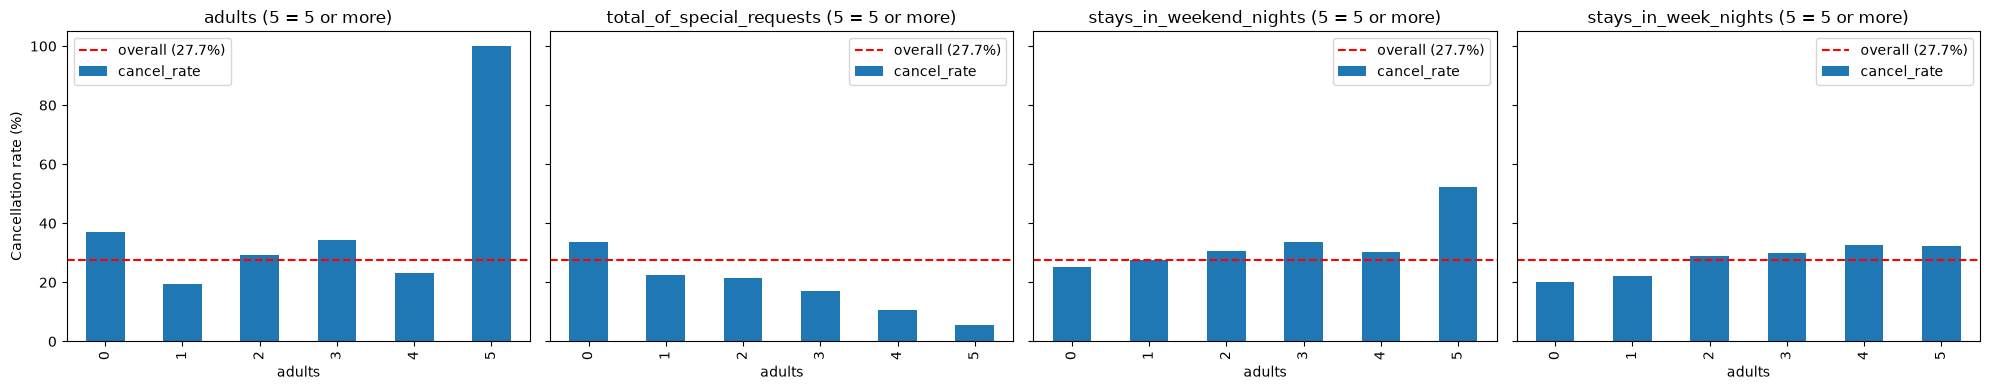

In [25]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4), sharey=True)
for ax, var in zip(axes, count_vars):
    count_table.loc[var, "cancel_rate"].plot(kind="bar", ax=ax)
    ax.axhline(overall_rate, color="red", linestyle="--", label=f"overall ({overall_rate:.1f}%)")
    ax.set_title(f"{var} (5 = 5 or more)")
    ax.legend()
axes[0].set_ylabel("Cancellation rate (%)")
plt.tight_layout()
plt.show()

As in 4a, bars above the red line cancel more than average. Very small groups (for example 5 or more adults, only 3 bookings) are shown but shouldn't be read as a pattern.

### Conclusions and actions: count variables vs. the target

**Conclusions**

- Three yes/no variables separate the classes very strongly:
  - `asked_for_parking`: none of the 7,290 bookings with a parking request was cancelled (0.0% vs
    30.2%). A perfect 0% isn't believable as customer behaviour; it strongly suggests the parking space
    is only recorded once the guest arrives.
  - `has_previous_cancellations`: customers who have cancelled before cancel again 68.2% of the time
    (1,677 bookings), more than twice the overall rate.
  - `has_previous_bookings`: customers with earlier bookings that went ahead almost never cancel
    (5.0%, 3,507 bookings).

- Bookings with changes are cancelled less (15.6% vs 30.3%), which is the opposite of what one might
  expect. Changes are counted until check-in or cancellation, so a booking that reaches the hotel has
  more time and chances to be changed: the variable partly reflects what happened after the booking.

- The more special requests, the lower the rate: 33.5% with none, 22.5% with one, 17.2% with three.
  Customers who take the time to ask for something seem more committed to the stay.

- Bookings with children or babies cancel more (34.4% vs 26.9%). Solo travellers cancel the least
  (19.6%), compared with 29.1% for two adults and 34.3% for three; groups of four or more are too small
  to read (63 bookings).

- Longer stays cancel slightly more: from 20.2% with no week nights to about 32% with four or more,
  in line with the long stays flagged in `02_outliers`.

**Actions**

- Use the yes/no versions of previous cancellations, previous bookings and children as features, and
  `total_of_special_requests` as a count capped at 3 or as yes/no.

- Keep `adults` and the nights as counts, capping the rare high values.

- `asked_for_parking` and `booking_changes` go to section 5 as strong leakage candidates. The perfect
  0% for parking is the clearest warning sign found so far.

### 4c. Categorical and date variables

In [26]:
cat_vars = ["hotel", "deposit_type", "customer_type", "market_segment",
            "distribution_channel", "meal", "is_repeated_guest"]
cat_table = pd.concat({var: cancel_rate(var) for var in cat_vars})
cat_table

bookings  cancel_rate  diff_vs_overall
hotel                City Hotel          53040         30.2              2.5
                     Resort Hotel        33581         23.7             -4.0
deposit_type         No Deposit          85477         26.9             -0.8
                     Non Refund           1037         94.7             67.0
                     Refundable            107         24.3             -3.4
customer_type        Contract             3118         16.4            -11.3
                     Group                 523          7.6            -20.1
                     Transient           71364         30.3              2.6
                     Transient-Party     11616         15.3            -12.4
market_segment       Aviation              222         19.8             -7.9
                     Complementary         682         12.2            -15.5
                     Corporate            4154         12.2            -15.5
                     Direct              11644         14.8            -12.9
                     Groups               4891         27.2             -0.5
                     Offline TA/TO       13742         14.9            -12.8
                     Online TA           51284         35.5              7.8
                     Undefined               2        100.0             72.3
distribution_channel Corporate            5000         12.8            -14.9
                     Direct              12795         14.9            -12.8
                     GDS                   178         20.2             -7.5
                     TA/TO               68643         31.1              3.4
                     Undefined               5         80.0             52.3
meal                 BB                  67404         26.7             -1.0
                     FB                    359         27.6             -0.1
                     HB                   9027         27.1             -0.6
                     SC                   9346         35.7              8.0
                     Undefined             485         16.9            -10.8
is_repeated_guest    0                   83477         28.4              0.7
                     1                    3144          8.2            -19.5

The same `cancel_rate` function is applied to each categorical variable. Categories with only a few
bookings (for example "Undefined") are shown but not interpreted.

In [27]:
non_refund = df[df["deposit_type"] == "Non Refund"]
display(non_refund["market_segment"].value_counts(normalize=True).round(3).head(3),
        non_refund["country"].value_counts(normalize=True).round(3).head(3),
        pd.crosstab(df["meal"], df["hotel"]))

market_segment
Groups           0.635
Offline TA/TO    0.276
Corporate        0.062
Name: proportion, dtype: float64

country
PRT    0.947
GBR    0.014
DEU    0.013
Name: proportion, dtype: float64

hotel,City Hotel,Resort Hotel
meal,,
BB,40981,26423
FB,11,348
HB,2774,6253
SC,9274,72
Undefined,0,485


Two results need a closer look: who makes the "Non Refund" bookings, and in which hotel each `meal`
category is used. `pd.crosstab` counts the bookings for each combination of meal and hotel.

In [28]:
room_changed = df["reserved_room_type"] != df["assigned_room_type"]
cancel_rate(room_changed)

,bookings,cancel_rate,diff_vs_overall
False,73962,31.6,3.9
True,12659,4.8,-22.9


`True` means the booking ended up in a different room type from the one reserved.

In [29]:
top_countries = df["country"].value_counts().head(10).index
country_group = df["country"].where(df["country"].isin(top_countries), "Other")
top_agents = df["agent"].value_counts().head(10).index
agent_group = df["agent"].where(df["agent"].isin(top_agents), "Other")
display(cancel_rate(country_group).sort_values("bookings", ascending=False),
        cancel_rate(agent_group).sort_values("bookings", ascending=False),
        cancel_rate(df["company"] != "No company"))

,bookings,cancel_rate,diff_vs_overall
country,,,
PRT,26848,36.3,8.6
Other,15904,27.4,-0.3
GBR,10399,19.1,-8.6
FRA,8813,19.6,-8.1
ESP,7228,25.7,-2.0
DEU,5385,19.6,-8.1
ITA,3056,35.1,7.4
IRL,3014,22.2,-5.5
BEL,2078,19.7,-8.0


,bookings,cancel_rate,diff_vs_overall
agent,,,
9,28653,40.2,12.5
Other,18034,18.4,-9.3
240,12907,38.3,10.6
No agent,11950,12.8,-14.9
14,3329,17.5,-10.2
7,3282,13.3,-14.4
250,2766,17.8,-9.9
241,1628,13.3,-14.4
28,1476,5.9,-21.8


,bookings,cancel_rate,diff_vs_overall
company,,,
False,81451,28.7,1.0
True,5170,10.9,-16.8


`country` and `agent` are reduced to their 10 most frequent values plus "Other" (`.where` keeps the
value if it is in the top 10 and replaces it with "Other" otherwise), as proposed in section 3c.
`company` is reduced to yes/no.

In [30]:
month_table = cancel_rate("arrival_date_month").reindex(month_order)
month_table

,bookings,cancel_rate,diff_vs_overall
arrival_date_month,,,
January,4637,22.3,-5.4
February,6030,23.3,-4.4
March,7438,24.5,-3.2
April,7870,30.5,2.8
May,8296,29.4,1.7
June,7721,30.4,2.7
July,9987,32.0,4.3
August,11194,32.4,4.7
September,6651,24.5,-3.2


`.reindex(month_order)` puts the months in calendar order, using the list defined in section 3c.
Unlike the counts in 3c, rates are not distorted by July and August appearing in three years.

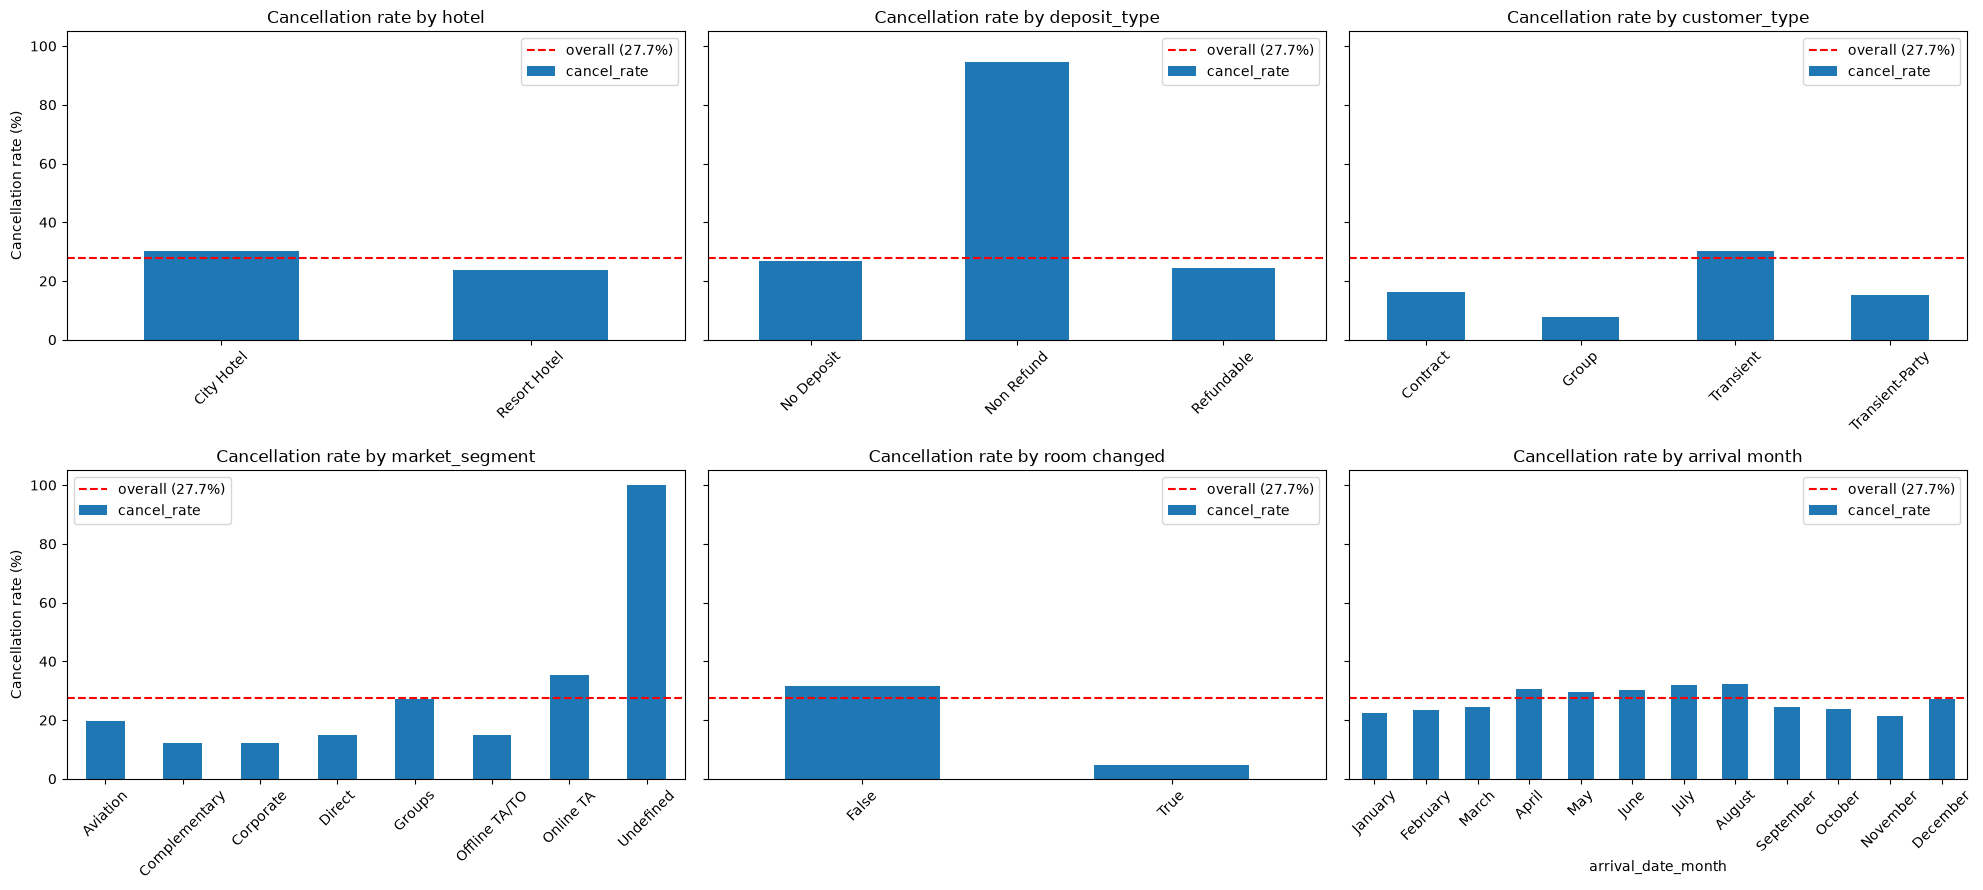

In [31]:
plot_tables = {"hotel": cat_table.loc["hotel"], "deposit_type": cat_table.loc["deposit_type"],
               "customer_type": cat_table.loc["customer_type"],
               "market_segment": cat_table.loc["market_segment"],
               "room changed": cancel_rate(room_changed), "arrival month": month_table}
fig, axes = plt.subplots(2, 3, figsize=(20, 9), sharey=True)
for ax, (name, table) in zip(axes.flat, plot_tables.items()):
    table["cancel_rate"].plot(kind="bar", ax=ax)
    ax.axhline(overall_rate, color="red", linestyle="--", label=f"overall ({overall_rate:.1f}%)")
    ax.set_title(f"Cancellation rate by {name}")
    ax.tick_params(axis="x", rotation=45)
    ax.legend()
axes[0, 0].set_ylabel("Cancellation rate (%)")
axes[1, 0].set_ylabel("Cancellation rate (%)")
plt.tight_layout()
plt.show()

### Conclusions and actions: categorical and date variables vs. the target

**Conclusions**

- `deposit_type` gives the most surprising result: 94.7% of "Non Refund" bookings were cancelled
  (1,037 bookings), the opposite of what the name suggests. Almost all of them are *Groups* (63.5%) or
  *Offline TA/TO* (27.6%) bookings from Portugal (94.7%), which points to blocks of rooms reserved by
  groups and agencies and later released, rather than to individual customers.

- Individual bookings made online cancel the most: *Transient* customers 30.3%, the *Online TA* segment
  35.5% (59% of all bookings). Bookings backed by an agreement cancel much less: *Contract* 16.4%,
  *Corporate* 12.2%, *Group* 7.6%, *Direct* 14.8%, and bookings through a company 10.9%.

- Repeated guests rarely cancel (8.2% vs 28.4%), the same message as previous bookings in 4b.

- Bookings that ended up in a different room type are almost never cancelled (4.8% vs 31.6%,
  12,659 bookings). The room is usually changed when the guest arrives, so a cancelled booking rarely
  gets a new one: this confirms `assigned_room_type` as a leakage variable.

- The City Hotel cancels more than the Resort Hotel (30.2% vs 23.7%).

- Portuguese customers cancel the most (36.3%), together with Brazil (36.5%) and Italy (35.1%), while
  the UK, France, Germany and the Netherlands are around 18–20%. Part of the Portuguese rate comes from
  the "Non Refund" group bookings above.

- Agents differ a lot: agent 9, the largest (28,653 bookings), has 40.2% and agent 240 has 38.3%,
  compared with 12.8% for bookings without an agent and 5.9% for agent 28.

- "SC" (35.7%) and "Undefined" (16.9%) mean the same meal plan but cancel very differently. The
  crosstab explains it: "Undefined" is used only by the Resort Hotel and "SC" almost only by the City
  Hotel, so the gap is the hotel effect.

- Cancellations are seasonal: highest in summer (July 32.0%, August 32.4%) and spring (April–June
  around 30%), lowest in November (21.4%) and January (22.3%).

**Actions**

- Candidate features: `deposit_type`, `customer_type`, `market_segment`, `hotel`, `is_repeated_guest`,
  `company` (yes/no), `agent` and `country` (top 10 + "Other") and the arrival month.
  `market_segment` and `distribution_channel` describe almost the same thing, so a model may only
  need one of them.

- Keep `deposit_type`, but note in the README that "Non Refund" reflects group and agency blocks.

- Merge "Undefined" into "SC" as planned: the difference between them is the hotel, not the meal.

- Group the tiny "Undefined" categories of `market_segment` (2) and `distribution_channel` (5) into
  "Other"; their extreme rates are noise.

- `assigned_room_type` is excluded; section 5 records the decision together with the other leakage
  candidates.

## 5. Leakage check and useful variables
The model is meant to predict, **when a booking is made**, whether it will be cancelled, so a variable
can only be a feature if its value is known at that moment. This matters here because, according to the
original paper (Antonio, de Almeida and Nunes, 2019), each booking's values were taken on the day before
arrival, and guests who arrive can still change their booking at check-in. Some columns therefore
describe what happened after the booking, not the booking itself.

In [32]:
pd.crosstab(df["reservation_status"], df[target])

is_canceled,0,1
reservation_status,,
Canceled,0,22972
Check-Out,62650,0
No-Show,0,999


Every *Canceled* and *No-Show* booking has `is_canceled = 1` and every *Check-Out* has 0:
`reservation_status` is the target written in words, and `reservation_status_date` is the date it was set.

In [33]:
leak_checks = {
    "room changed (assigned != reserved)": df["reserved_room_type"] != df["assigned_room_type"],
    "asked for parking": df["required_car_parking_spaces"] > 0,
    "has booking changes": df["booking_changes"] > 0,
    "on waiting list": df["days_in_waiting_list"] > 0,
}
leak_table = pd.concat({name: cancel_rate(flag) for name, flag in leak_checks.items()})
leak_table

bookings  cancel_rate  \
room changed (assigned != reserved) False     73962         31.6   
                                    True      12659          4.8   
asked for parking                   False     79331         30.2   
                                    True       7290          0.0   
has booking changes                 False     70943         30.3   
                                    True      15678         15.6   
on waiting list                     False     85767         27.6   
                                    True        854         34.4   

                                           diff_vs_overall  
room changed (assigned != reserved) False              3.9  
                                    True             -22.9  
asked for parking                   False              2.5  
                                    True             -27.7  
has booking changes                 False              2.6  
                                    True             -12.1  
on waiting list                     False             -0.1  
                                    True               6.7

The four candidates flagged in sections 3 and 4, side by side. A strong effect is not a problem in
itself; the problem is a value that is filled in after the booking is made.

| Variable | When is the value known? | Evidence | Decision |
|---|---|---|---|
| `reservation_status`, `reservation_status_date` | After the outcome | Match the target exactly | **Exclude** |
| `assigned_room_type` | Decided by the hotel, often at check-in | Room changed: 4.8% cancelled vs 31.6% | **Exclude** (use `reserved_room_type`) |
| `required_car_parking_spaces` | Most likely recorded when the guest arrives | 0.0% cancelled out of 7,290 | **Exclude** |
| `booking_changes` | Counted from the moment the booking is entered, so it grows afterwards | With changes: 15.6% vs 30.3% | **Exclude** |
| `days_in_waiting_list` | Only fixed once the booking is confirmed | 34.4% vs 27.6%, only 854 bookings | **Exclude** (little to lose) |
| `adults`, `children`, nights, `meal`, `country` | Known at booking, but can change at check-in (the paper notes their distributions differ for this reason) | Moderate differences | Keep, with caution |
| `adr`, `total_of_special_requests` | Known at booking, but `adr` is computed from lodging transactions and requests can be added before arrival | Moderate, steady patterns | Keep, with caution |

Two more columns are left out for other reasons: `arrival_date_year`, because a model is applied to
future years it has never seen, and `arrival_date_week_number`, which repeats the month.

In [34]:
excluded = leakage + ["assigned_room_type", "required_car_parking_spaces", "booking_changes",
                      "days_in_waiting_list", "arrival_date_year", "arrival_date_week_number"]
features = [c for c in df.columns if c not in excluded + [target]]
print(len(features), "candidate features:")
print(features)

23 candidate features:
['hotel', 'lead_time', 'arrival_date_month', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'deposit_type', 'agent', 'company', 'customer_type', 'adr', 'total_of_special_requests']


`features` is the list of columns a model could use, before the transformations proposed in sections 3
and 4 (yes/no versions, grouping rare categories, capping counts). It is the feature vector described
in the README.

### Conclusions and actions: leakage check and useful variables

**Conclusions**

- Two columns give away the outcome (`reservation_status`, `reservation_status_date`) and four more are
  recorded or updated after the booking is made (`assigned_room_type`, `required_car_parking_spaces`,
  `booking_changes`, `days_in_waiting_list`). The clearest sign is parking: a 0% cancellation rate is not
  a pattern a model should learn, because when the booking is made nobody knows yet whether the guest will
  ask for a parking space.

- Without them, and leaving out `arrival_date_year` and `arrival_date_week_number`, 23 candidate features
  remain.

- Among the features kept, the strongest relationships in section 4 are `deposit_type` ("Non Refund"
  94.7%), `lead_time` (from 8.5% to 41%), previous cancellations (68.2%) and previous bookings (5.0%),
  repeated guests (8.2%), `customer_type`, `market_segment`, `agent` and `country`. Moderate: `adr`,
  special requests, `hotel`, the month, children, `company`, `adults` and the nights. Weak: `meal`.

- Some kept variables carry a smaller risk: guests can change the number of people, the nights or the
  meal at check-in, and `country` can also differ, so their effects should be read with that in mind.

**Actions**

- Use the 23 columns in `features` for modelling, with the transformations proposed earlier: yes/no
  versions of the mostly-zero counts, top 10 + "Other" for `country` and `agent`, "Undefined" merged into
  "SC" in `meal`, rare segments grouped, and bins or a log transform for `lead_time`.

- List the excluded columns and the reason for each in the README's problem formulation.

- If a model later looks "too good", check the "keep, with caution" variables first.

## Final summary

- After cleaning, 27.7% of bookings are cancelled. Always predicting "not canceled" already gives
  72.3% accuracy, so models should be judged with recall, precision and AUC as well.

- Cancellations are more likely for bookings made far in advance, "Non Refund" group and agency blocks,
  online travel agency bookings and customers who have cancelled before. They are less likely for
  repeated guests, bookings through a company or contract, and guests who make special requests.

- Six columns are excluded for leakage, and two date columns for other reasons. 23 candidate features
  remain, with the transformations listed in each section's actions.